# 📊 Telco Customer Churn — End-to-End Data Science Project

**Author:** Manoj Chaandu
**Dataset:** `WA_Fn-UseC_-Telco-Customer-Churn.csv` (7,043 Customers, 21 Features)  
**Companion Dashboard:** Built alongside my first Power BI Dashboard (*Telco Customer Churn*)

---

###  1. Project Overview & Problem Statement

In the telecom industry, acquiring a new customer costs much more than keeping an existing one. **Customer Churn** happens when a subscriber cancels their service and leaves the company.

After building my first interactive **Power BI Dashboard** to visualize churn rates across contracts, billing methods, and demographics, I wanted to take the next step and build a complete **Python Data Science Project** on the same dataset.

####  My Goals in This Notebook:
1. **Understand the Data:** Load the CSV file and inspect all 21 columns (customer demographics, account details, and subscribed services).
2. **Clean the Data:** Fix data type issues (like `TotalCharges` being stored as text) and handle missing values properly.
3. **Exploratory Data Analysis (EDA):** Verify the exact numbers from my Power BI dashboard (`7,043` total customers, `1,869` churned / `26.54%` churn rate) and explore deeper patterns using `matplotlib` and `seaborn`.
4. **Feature Engineering & Preprocessing:** Convert categorical text columns into numbers and scale numerical features so Machine Learning models can understand them.
5. **Model Building & Evaluation:** Train and compare three classic classification models (**Logistic Regression**, **Decision Tree**, and **Random Forest**) to predict which customers are likely to churn.
6. **Business Recommendations:** Share practical, easy-to-understand suggestions that a telecom team can use to reduce churn.

##  Step 1: Importing Libraries & Loading the Dataset

First, I am importing the core Python libraries that I learned for data analysis, visualization, and machine learning:
- `pandas` and `numpy` for data handling and math operations.
- `matplotlib` and `seaborn` for plotting clean charts.
- `scikit-learn` (`sklearn`) for splitting data, scaling features, and training machine learning models.

In [1]:
# Importing basic libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Setting plot style and matching the Blue & Orange color palette from my Power BI dashboard
plt.style.use('seaborn-v0_8-whitegrid')
PALETTE = {'No': '#2B7BBA', 'Yes': '#E85D24'}

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load the Telco Customer Churn dataset
df = pd.read_csv(r'C:\Users\manoj\OneDrive\Desktop\Telco customer churn\WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Check the number of rows and columns
print(f"Dataset Shape: {df.shape[0]} rows (customers) and {df.shape[1]} columns (features)")

# Preview the first 5 rows of the dataset
df.head()

Dataset Shape: 7043 rows (customers) and 21 columns (features)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


###  What I Observed from the First 5 Rows:
- Each row represents **one unique customer** identified by `customerID`.
- We have **demographic columns** (`gender`, `SeniorCitizen`, `Partner`, `Dependents`).
- We have **service subscription columns** (`PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `TechSupport`, etc.).
- We have **account & billing columns** (`tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`).
- Finally, **`Churn`** is our **target column** (`Yes` = customer left the company, `No` = customer stayed).

Let's check the data types and summary information of all 21 columns using `.info()`.

In [3]:
# Check column names, non-null counts, and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


##  Step 2: Data Cleaning & Preprocessing

When I looked at the `.info()` output above, I noticed something interesting:
- `MonthlyCharges` is a `float64` (decimal number), and `tenure` is an `int64` (whole number).
- However, **`TotalCharges` is listed as an `object` (text/string)** instead of a number!

Let's investigate why `TotalCharges` is stored as text. Usually, this happens when there are blank spaces (`" "`) in the CSV file.

In [4]:
# Check if there are blank spaces in the TotalCharges column
blank_charges = df[df['TotalCharges'] == ' ']
print(f"Number of rows where TotalCharges is a blank space: {len(blank_charges)}")

# Let's see the tenure and MonthlyCharges for these 11 customers
blank_charges[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Number of rows where TotalCharges is a blank space: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


###  Why Are Those 11 `TotalCharges` Values Blank?
Looking at the table above, **all 11 of these customers have `tenure == 0`** (they just signed up this month and haven't completed their first billing cycle yet, and none of them have churned).

#### How I Decided to Fix This:
1. I will convert `TotalCharges` to a numeric column using `pd.to_numeric(df['TotalCharges'], errors='coerce')`, which turns those 11 blank spaces into `NaN` (missing values).
2. Since their `tenure` is `0` months, their total billed amount so far is `$0.0`. So filling those 11 missing values with `0` makes complete business sense (and we don't lose any of our `7,043` customers!).
3. I will also check for duplicate rows and drop the `customerID` column later when preparing for modeling because an ID number does not help predict churn.

In [5]:
# 1. Convert TotalCharges to numeric (blank spaces become NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check missing values count before filling
print("Missing values in TotalCharges before filling:", df['TotalCharges'].isnull().sum())

# 2. Fill the 11 missing values with 0 (since their tenure is 0 months)
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 3. Verify missing values and check for duplicate rows
print("Missing values in entire dataset after fixing:", df.isnull().sum().sum())
print("Number of duplicate rows:", df.duplicated().sum())
print("New data type of TotalCharges:", df['TotalCharges'].dtype)

Missing values in TotalCharges before filling: 11
Missing values in entire dataset after fixing: 0
Number of duplicate rows: 0
New data type of TotalCharges: float64


In [6]:
# Summary statistics of our numerical columns
df[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


###  Quick Summary of Numerical Features:
- **`tenure`**: Ranges from `0` to `72` months (6 years), with an average of **`32.37` months**.
- **`MonthlyCharges`**: Ranges from **`$18.25`** to **`$118.75`**, with an average monthly bill of **`$64.76`**.
- **`TotalCharges`**: Ranges from **`$0.00`** to **`$8,684.80`**, with an average of **`$2,279.73`**.

##  Step 3: Exploratory Data Analysis (EDA)

Now comes my favorite part! In this section, I will explore the data visually using `matplotlib` and `seaborn`. I also want to verify how the numbers in Python match the KPI cards and charts I built in my **Power BI Dashboard**:
- **Total Customers:** `7,043`
- **Churned Customers:** `1,869` (`26.54%`)
- **Retained Customers:** `5,174` (`73.46%`)

### 3.1 Overall Customer Churn Distribution

--- Overall Churn Breakdown (Matches Power BI KPI Cards) ---
       Customer Count  Percentage (%)
Churn                                
No               5174           73.46
Yes              1869           26.54


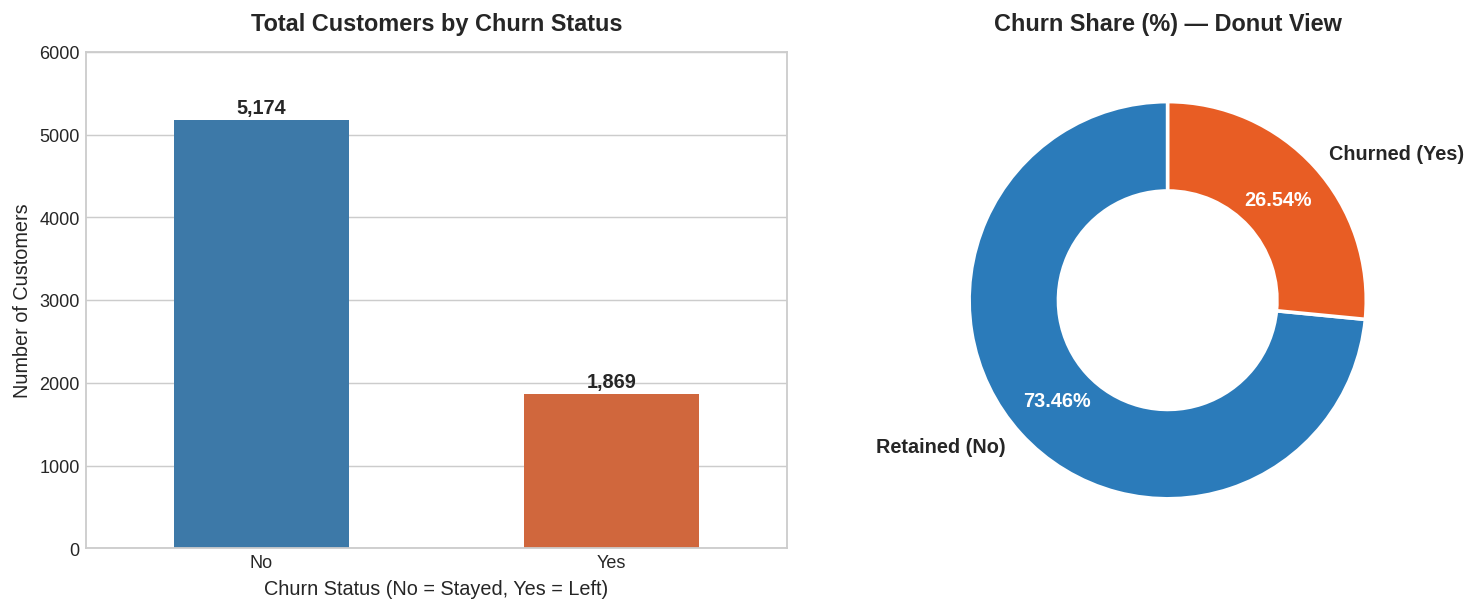

In [7]:
# Count and percentage of Churn
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({
    'Customer Count': churn_counts,
    'Percentage (%)': churn_pct.round(2)
})
print("--- Overall Churn Breakdown (Matches Power BI KPI Cards) ---")
print(summary_df)

# Plotting Count Bar Chart and Donut Chart side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left plot: Bar chart of customer counts
bars = sns.countplot(data=df, x='Churn', palette=PALETTE, ax=axes[0], width=0.5)
axes[0].set_title('Total Customers by Churn Status', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Churn Status (No = Stayed, Yes = Left)', fontsize=11)
axes[0].set_ylabel('Number of Customers', fontsize=11)
axes[0].set_ylim(0, 6000)

for p in axes[0].patches:
    height = int(p.get_height())
    axes[0].annotate(f'{height:,}', (p.get_x() + p.get_width() / 2., height + 150),
                     ha='center', va='center', fontsize=11, fontweight='bold')

# Right plot: Donut chart (just like my Power BI visual!)
colors = [PALETTE['No'], PALETTE['Yes']]
wedges, texts, autotexts = axes[1].pie(
    churn_counts,
    labels=['Retained (No)', 'Churned (Yes)'],
    autopct='%1.2f%%',
    startangle=90,
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=11, fontweight='bold')
)
for autotext in autotexts:
    autotext.set_color('white')
axes[1].set_title('Churn Share (%) — Donut View', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

###  Observation:
- Out of **7,043** total customers, **1,869 customers (`26.54%`) have churned**, while **5,174 customers (`73.46%`) stayed**.
- This also tells me that our dataset is **moderately imbalanced** (roughly a 73:27 split between `No` and `Yes`). Because of this, when I evaluate my Machine Learning models later, I shouldn't rely only on **Accuracy**—I also need to check **Precision, Recall, F1-Score, and ROC-AUC**.

---

### 3.2 Churn Rate by Customer Demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`)

In my Power BI dashboard, I created three bar charts comparing churn rates across **Partner Status**, **Dependents**, and **Gender**. Let's plot these demographic features in Python and also include **Senior Citizen** status to see who is most likely to leave.

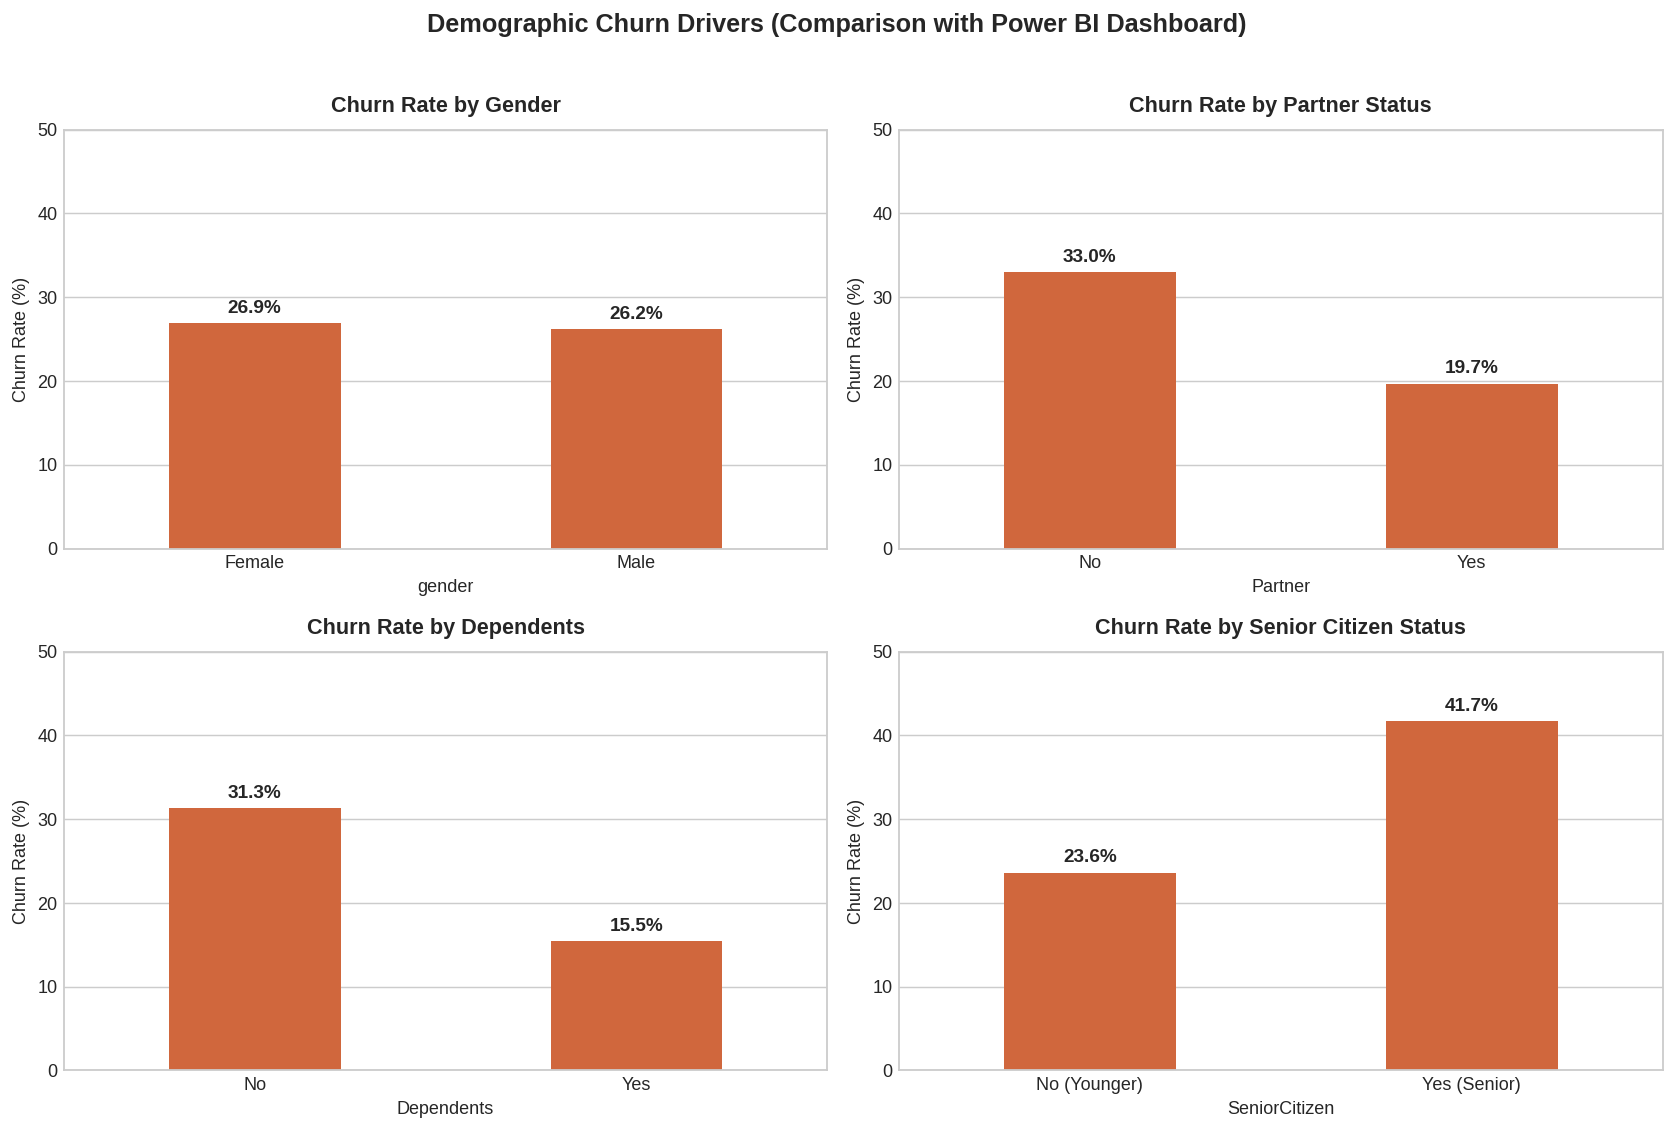

In [8]:
# Create a temporary readable column for SeniorCitizen (0 -> No, 1 -> Yes) for plotting
df['SeniorCitizen_Label'] = df['SeniorCitizen'].map({0: 'No (Younger)', 1: 'Yes (Senior)'})

demo_cols = [
    ('gender', 'Churn Rate by Gender'),
    ('Partner', 'Churn Rate by Partner Status'),
    ('Dependents', 'Churn Rate by Dependents'),
    ('SeniorCitizen_Label', 'Churn Rate by Senior Citizen Status')
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
axes = axes.flatten()

for i, (col, title) in enumerate(demo_cols):
    # Calculate exact churn rate (%) for each category
    churn_rate = df.groupby(col)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
    churn_rate.columns = [col, 'Churn_Rate_Pct']
    
    sns.barplot(data=churn_rate, x=col, y='Churn_Rate_Pct', color='#E85D24', ax=axes[i], width=0.45)
    axes[i].set_title(title, fontsize=12, fontweight='bold', pad=10)
    axes[i].set_xlabel(col.replace('_Label', ''), fontsize=10)
    axes[i].set_ylabel('Churn Rate (%)', fontsize=10)
    axes[i].set_ylim(0, 50)
    
    # Add percentage labels on top of each bar
    for p in axes[i].patches:
        val = p.get_height()
        axes[i].annotate(f'{val:.1f}%', (p.get_x() + p.get_width() / 2., val + 1.8),
                         ha='center', va='center', fontsize=10.5, fontweight='bold')

plt.suptitle('Demographic Churn Drivers (Comparison with Power BI Dashboard)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Clean up temporary label column
df.drop(columns=['SeniorCitizen_Label'], inplace=True)

###  Key Takeaways from Demographics:
1. **Gender does NOT affect churn:** Female churn rate (`26.9%`) and Male churn rate (`26.2%`) are almost identical.
2. **Customers without a Partner churn much more:** Single customers (`Partner = No`) have a **`33.0%` churn rate**, compared to only **`19.7%`** for customers with a partner.
3. **Customers without Dependents are twice as likely to leave:** Customers with `Dependents = No` churn at **`31.3%`**, whereas families with dependents churn at only **`15.5%`**.
4. **Senior Citizens are a high-risk group:** Senior citizens churn at **`41.7%`**, which is almost double the rate of younger customers (`23.6%`).

---

### 3.3 Contract Type, Tech Support & Payment Method (Major Churn Drivers!)

In my Power BI dashboard, the biggest spikes in churn came from **Month-to-Month contracts**, **No Tech Support**, and **Electronic Check payments**. Let's recreate these exact visuals in Python and inspect the numbers.

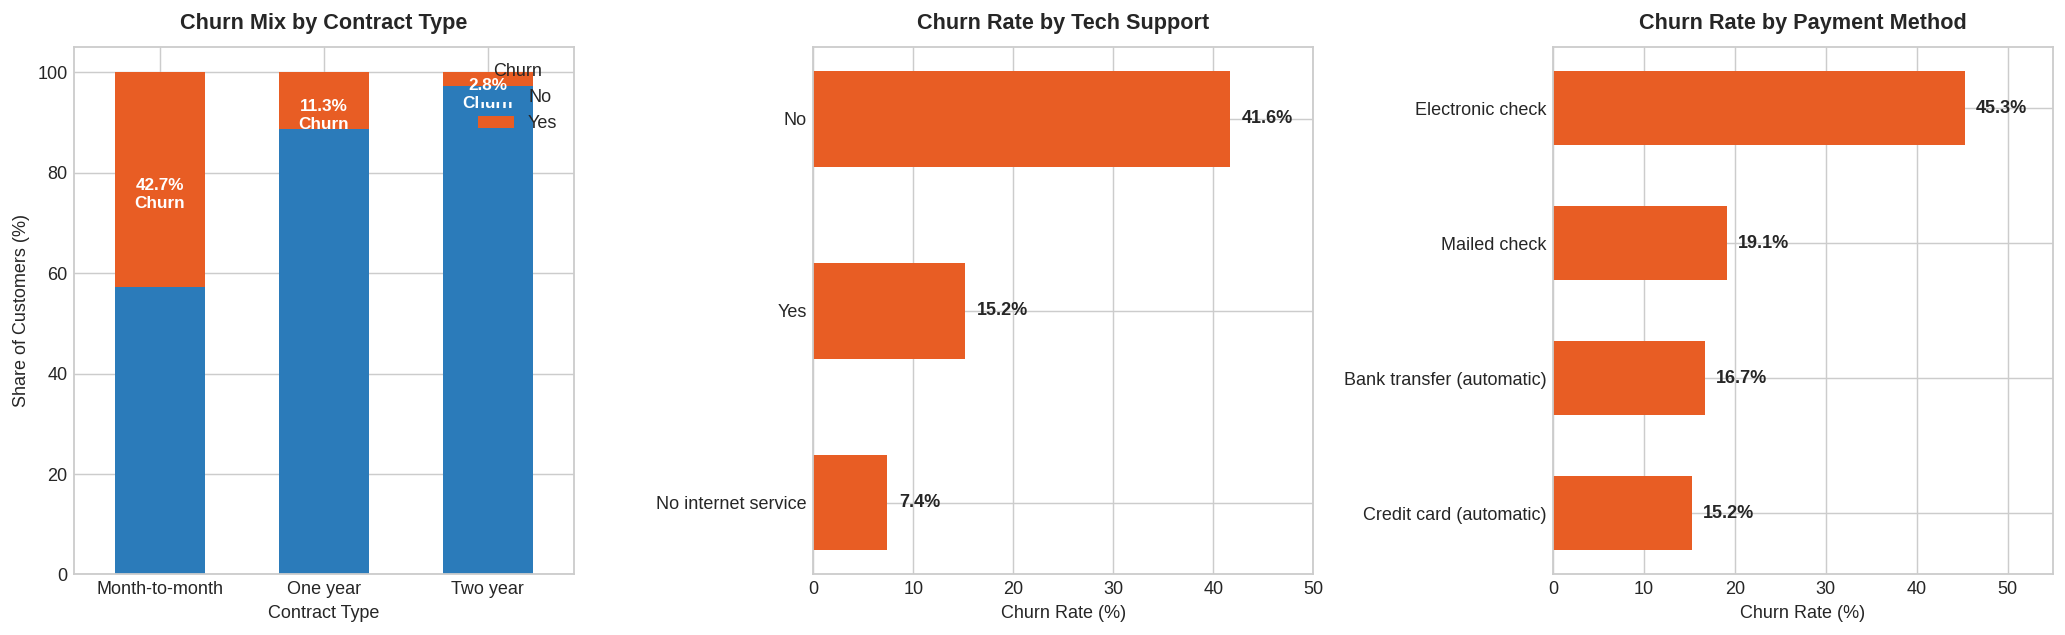

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Churn Mix by Contract (100% Stacked Bar - matching Power BI 'Churn Mix By Contract')
contract_ct = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
contract_ct = contract_ct.loc[['Month-to-month', 'One year', 'Two year']]
contract_ct.plot(kind='bar', stacked=True, color=[PALETTE['No'], PALETTE['Yes']], ax=axes[0], width=0.55)
axes[0].set_title('Churn Mix by Contract Type', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Contract Type', fontsize=10)
axes[0].set_ylabel('Share of Customers (%)', fontsize=10)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
axes[0].legend(title='Churn', loc='upper right')

for n, x in enumerate([*contract_ct.index.values]):
    churn_val = contract_ct.loc[x, 'Yes']
    axes[0].annotate(f'{churn_val:.1f}%\nChurn', (n, 100 - churn_val / 2 - 3),
                     ha='center', va='center', color='white', fontsize=9.5, fontweight='bold')

# 2. Churn Rate by TechSupport (Horizontal Bar - matching Power BI)
tech_churn = df.groupby('TechSupport')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).sort_values(ascending=True)
axes[1].barh(tech_churn.index, tech_churn.values, color='#E85D24', height=0.5)
axes[1].set_title('Churn Rate by Tech Support', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Churn Rate (%)', fontsize=10)
axes[1].set_xlim(0, 50)
for i, v in enumerate(tech_churn.values):
    axes[1].text(v + 1.2, i, f'{v:.1f}%', va='center', fontsize=10, fontweight='bold')

# 3. Churn Rate by PaymentMethod (Horizontal Bar - matching Power BI)
pay_churn = df.groupby('PaymentMethod')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).sort_values(ascending=True)
axes[2].barh(pay_churn.index, pay_churn.values, color='#E85D24', height=0.55)
axes[2].set_title('Churn Rate by Payment Method', fontsize=12, fontweight='bold', pad=10)
axes[2].set_xlabel('Churn Rate (%)', fontsize=10)
axes[2].set_xlim(0, 55)
for i, v in enumerate(pay_churn.values):
    axes[2].text(v + 1.2, i, f'{v:.1f}%', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

###  Why Are These Three Charts So Important?
1. **Contract Type is the #1 Retention Anchor:**
   - **Month-to-month** customers have an alarming **`42.7%` churn rate**!
   - Once a customer commits to a **One-year contract**, churn drops to **`11.3%`**.
   - On a **Two-year contract**, churn is tiny—just **`2.8%`**!
2. **Lack of Tech Support Drives Customers Away:**
   - Customers with **No Tech Support** have a **`41.6%` churn rate**, compared to only **`15.2%`** for customers who have Tech Support (and `7.4%` for customers without internet service).
3. **Electronic Check Users Churn at `45.3%`:**
   - Customers paying manually via **Electronic check** churn at **`45.3%`**, whereas customers on automatic payment methods (**Bank transfer** `16.7%` and **Credit card** `15.2%`) stay much longer.

---

### 3.4 Internet Service & Add-On Services Analysis

In my Power BI dashboard, I included `InternetService` as a top filter slicer. Let's see how churn varies across **Internet Service types** (`DSL`, `Fiber optic`, `No`) and other online services (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`).

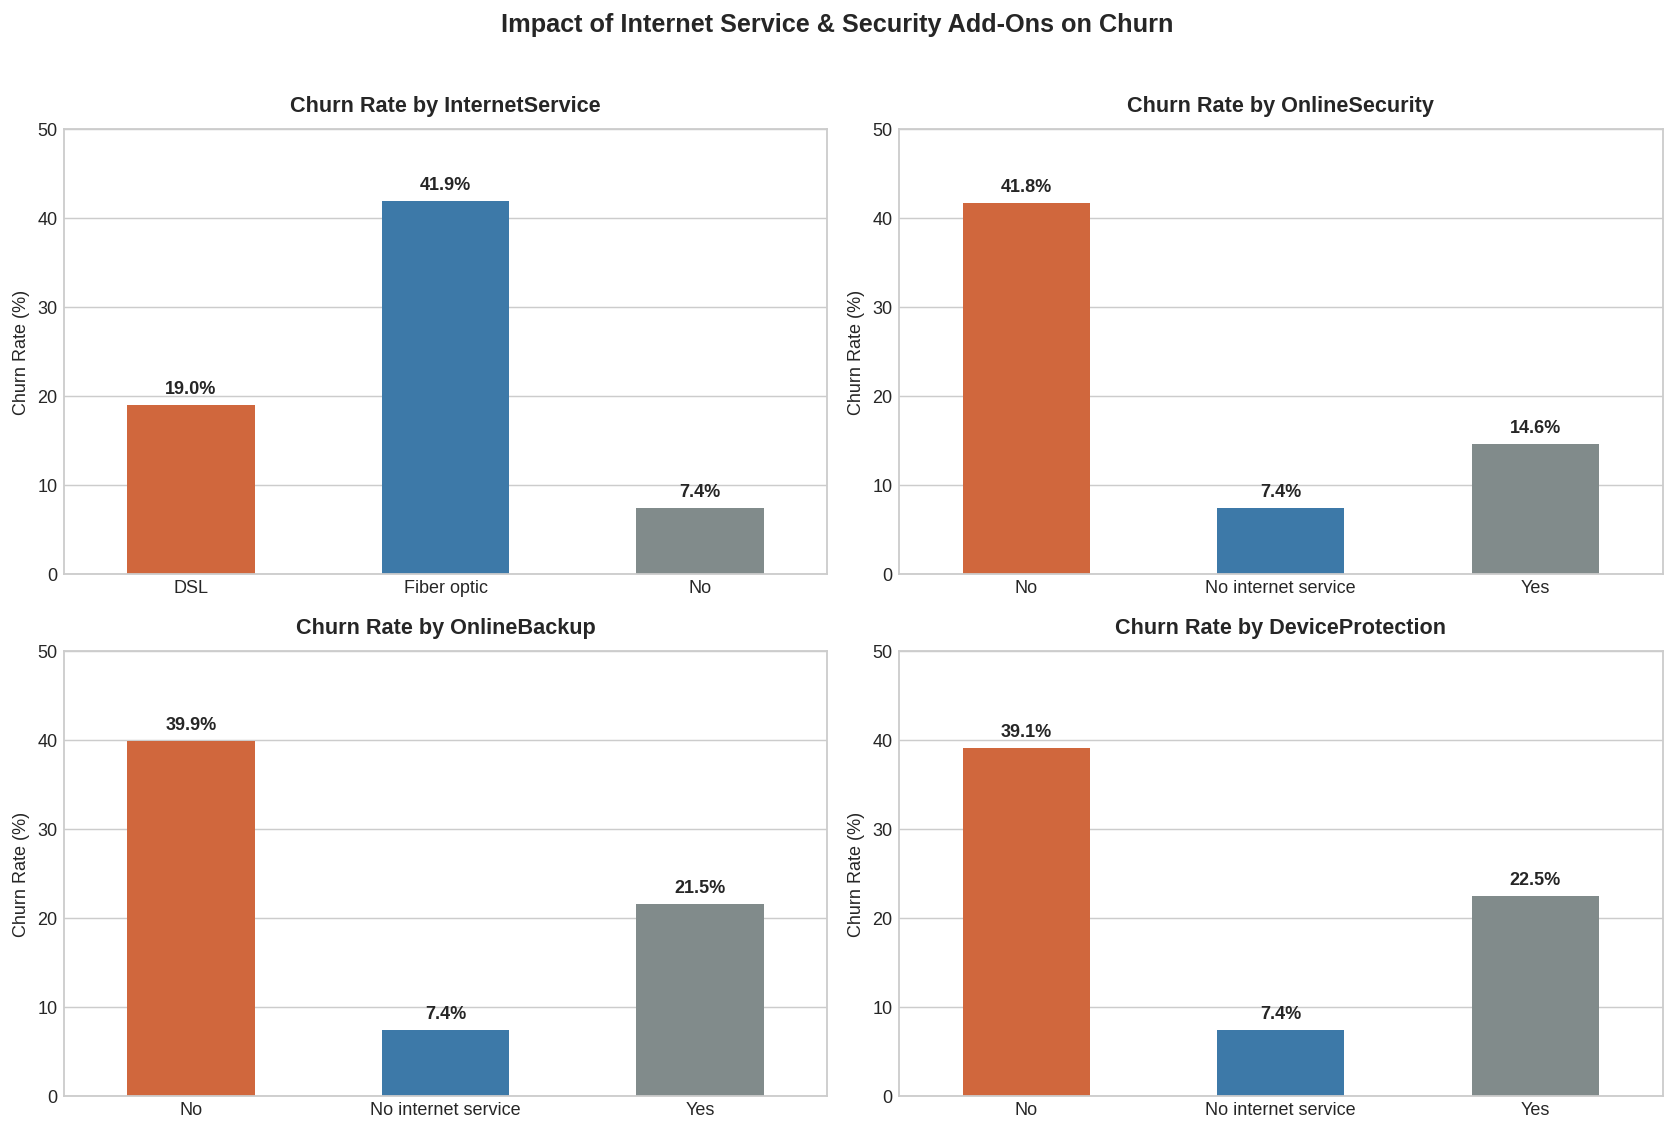

In [10]:
service_cols = ['InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection']

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
axes = axes.flatten()

for i, col in enumerate(service_cols):
    rates = df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).reset_index()
    rates.columns = [col, 'Churn_Rate']
    
    sns.barplot(data=rates, x=col, y='Churn_Rate', palette=['#E85D24', '#2B7BBA', '#7F8C8D'], ax=axes[i], width=0.5)
    axes[i].set_title(f'Churn Rate by {col}', fontsize=12, fontweight='bold', pad=10)
    axes[i].set_ylabel('Churn Rate (%)', fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylim(0, 50)
    
    for p in axes[i].patches:
        val = p.get_height()
        axes[i].annotate(f'{val:.1f}%', (p.get_x() + p.get_width() / 2., val + 1.8),
                         ha='center', va='center', fontsize=10, fontweight='bold')

plt.suptitle('Impact of Internet Service & Security Add-Ons on Churn', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

###  What I Learned from Internet & Add-on Services:
- **Fiber Optic Customers Have High Churn (`41.9%`):** Even though Fiber Optic is faster than DSL (`19.0%` churn), Fiber Optic customers are leaving at more than double the rate! This is likely because Fiber Optic plans are more expensive (higher `MonthlyCharges`) or customers experience service/pricing dissatisfaction without support add-ons.
- **Online Security & Backup Reduce Churn Significantly:** Customers without `OnlineSecurity` churn at **`41.8%`**, while those with `OnlineSecurity = Yes` churn at only **`14.6%`**.

---

### 3.5 Numerical Features Analysis (`tenure` & `MonthlyCharges`)

In my Power BI dashboard, the bar chart **"Average of Monthly Charge by Churn Status"** showed that customers who churn pay higher monthly bills on average. Let's verify the exact averages in Python and plot the full distributions of **`MonthlyCharges`** and **`tenure`**.

--- Numerical Summary by Churn Status ---
      tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55


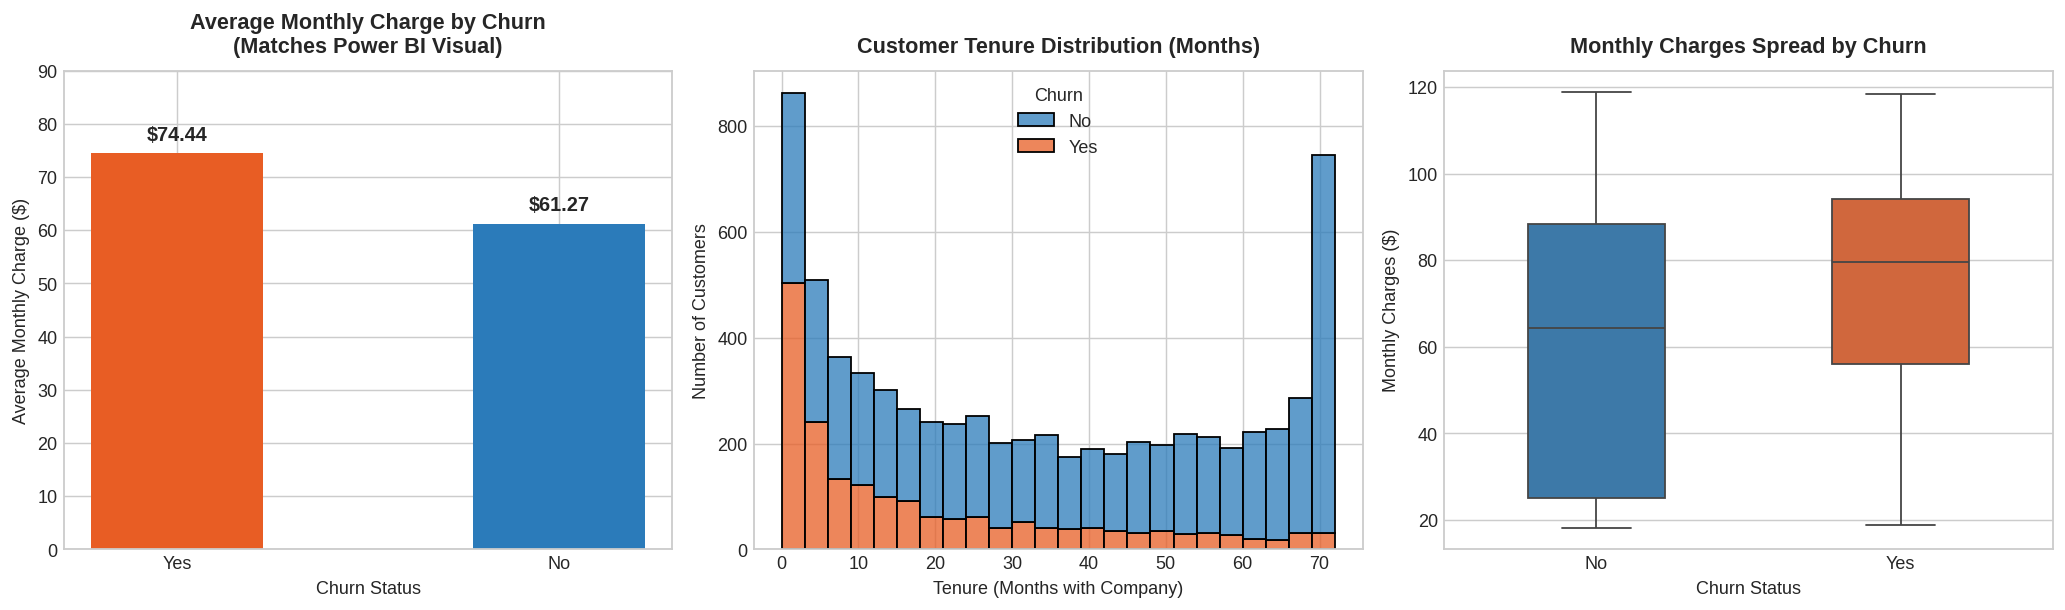

In [11]:
# Exact average and median of tenure, MonthlyCharges, and TotalCharges by Churn status
num_summary = df.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].agg(['mean', 'median']).round(2)
print("--- Numerical Summary by Churn Status ---")
print(num_summary)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. Average Monthly Charges Bar Chart (Matches Power BI chart directly)
avg_charge = df.groupby('Churn')['MonthlyCharges'].mean().loc[['Yes', 'No']]
axes[0].bar(avg_charge.index, avg_charge.values, color=[PALETTE['Yes'], PALETTE['No']], width=0.45)
axes[0].set_title('Average Monthly Charge by Churn\n(Matches Power BI Visual)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Churn Status', fontsize=10)
axes[0].set_ylabel('Average Monthly Charge ($)', fontsize=10)
axes[0].set_ylim(0, 90)
for i, v in enumerate(avg_charge.values):
    axes[0].text(i, v + 2.5, f'${v:.2f}', ha='center', fontsize=11, fontweight='bold')

# 2. Tenure Distribution by Churn
sns.histplot(data=df, x='tenure', hue='Churn', palette=PALETTE, multiple='stack', bins=24, ax=axes[1])
axes[1].set_title('Customer Tenure Distribution (Months)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Tenure (Months with Company)', fontsize=10)
axes[1].set_ylabel('Number of Customers', fontsize=10)

# 3. MonthlyCharges Boxplot by Churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette=PALETTE, width=0.45, ax=axes[2])
axes[2].set_title('Monthly Charges Spread by Churn', fontsize=12, fontweight='bold', pad=10)
axes[2].set_xlabel('Churn Status', fontsize=10)
axes[2].set_ylabel('Monthly Charges ($)', fontsize=10)

plt.tight_layout()
plt.show()

###  Insights from Tenure & Monthly Charges:
1. **Churned Customers Pay More Per Month:**
   - Average Monthly Charge for **Churned (`Yes`)** customers is **`$74.44`** (median `$79.65`).
   - Average Monthly Charge for **Retained (`No`)** customers is **`$61.27`** (median `$64.43`).
2. **The First 1 to 6 Months Are the Danger Zone (`tenure`):**
   - Look at the middle histogram: there is a huge orange spike (`Churn = Yes`) in the **first 1–5 months**!
   - The **median tenure of a customer who churns is only `10 months`**, whereas the **median tenure of a customer who stays is `38 months`** (over 3 years). If we can keep a customer happy through their first year, they are much more likely to stay long-term.

---

### 3.6 Correlation Heatmap of Numerical Features

Before moving to feature engineering, let's check how our numerical variables (`SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges`, and binary `Churn`) correlate with each other.

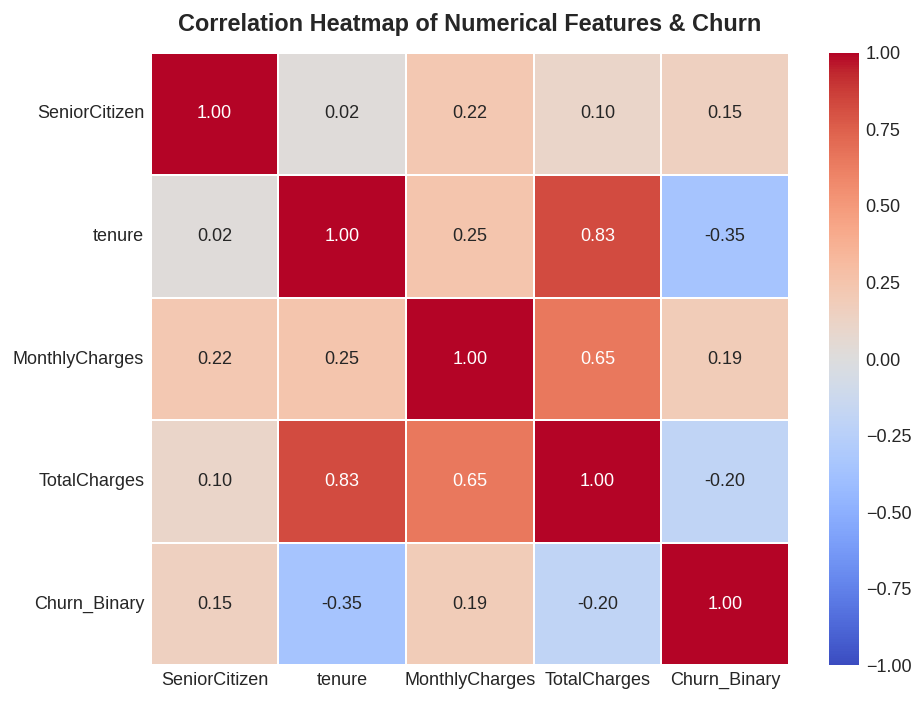

In [12]:
# Create a copy with binary Churn (1 = Yes, 0 = No) to check correlation
corr_df = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].copy()
corr_df['Churn_Binary'] = df['Churn'].map({'Yes': 1, 'No': 0})

plt.figure(figsize=(7.5, 5.5))
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=1)
plt.title('Correlation Heatmap of Numerical Features & Churn', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

###  What the Correlation Matrix Shows:
- **`tenure` vs `Churn_Binary` (`-0.35`):** Negative correlation—as tenure increases, the chance of churning goes down significantly.
- **`MonthlyCharges` vs `Churn_Binary` (`+0.19`):** Positive correlation—higher monthly bills are associated with higher churn.
- **`tenure` vs `TotalCharges` (`+0.83`):** Strong positive correlation, which makes sense because `TotalCharges` is roughly `tenure × MonthlyCharges`.

##  Step 4: Feature Engineering & Data Preprocessing

Machine Learning algorithms in `scikit-learn` only work with numbers—they cannot directly read text values like `"Yes"`, `"No"`, `"Fiber optic"`, or `"Month-to-month"`.

Here is the step-by-step preprocessing pipeline I followed:
1. **Drop `customerID`:** It is just a random identifier for each row and has no predictive value.
2. **Encode the Target Variable (`Churn`):** Map `'Yes' -> 1` and `'No' -> 0`.
3. **One-Hot Encoding (`pd.get_dummies`):** Convert categorical text columns into binary (`0` / `1`) indicator columns using `drop_first=True` (to avoid redundant dummy columns).
4. **Train-Test Split (`80%` Train / `20%` Test):** Split the dataset using `stratify=y` so both training and testing sets have the exact same `26.54%` churn ratio.
5. **Feature Scaling (`StandardScaler`):** Standardize `tenure`, `MonthlyCharges`, and `TotalCharges` so that large numbers (like `TotalCharges` in the thousands) don't overpower smaller features in Logistic Regression.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Make a clean copy and drop customerID
df_model = df.drop(columns=['customerID']).copy()

# 2. Convert target column 'Churn' into 0 and 1
df_model['Churn'] = df_model['Churn'].map({'No': 0, 'Yes': 1})

# 3. One-Hot Encode all categorical columns (drop_first=True prevents dummy variable trap)
df_encoded = pd.get_dummies(df_model, drop_first=True, dtype=int)

print(f"Shape before encoding: {df_model.shape}")
print(f"Shape after One-Hot Encoding: {df_encoded.shape}")

# Preview the encoded dataset
df_encoded.head()

Shape before encoding: (7043, 20)
Shape after One-Hot Encoding: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


In [14]:
# 4. Separate Features (X) and Target (y)
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

# Split into 80% Training data and 20% Testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Set: {X_train.shape[0]} customers ({y_train.mean()*100:.2f}% churn)")
print(f"Testing Set:  {X_test.shape[0]} customers ({y_test.mean()*100:.2f}% churn)")

# 5. Scale numerical columns (fit ONLY on X_train to prevent data leakage!)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("\nNumerical features scaled successfully!")

Training Set: 5634 customers (26.54% churn)
Testing Set:  1409 customers (26.54% churn)

Numerical features scaled successfully!


##  Step 5: Machine Learning Model Building

As a fresher, instead of jumping straight into a complex black-box model, I wanted to train and compare **three foundational classification models** that I can clearly explain:
1. **Logistic Regression:** Great baseline model for binary classification (`Churn = 0` or `1`). It estimates the probability of churn using a linear combination of features passed through a sigmoid function.
2. **Decision Tree Classifier:** Splits customers into groups using simple `if-else` rules (for example, *Is Contract == Month-to-month?* and *Is tenure <= 12?*). I set `max_depth=5` so the tree stays simple and doesn't memorize (overfit) the training data.
3. **Random Forest Classifier:** An ensemble model that builds many Decision Trees on random subsets of data and averages their predictions, which usually improves accuracy and stability.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Initialize the 3 models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
}

# Dictionary to store evaluation results and predictions
results = []
model_preds = {}
model_probs = {}

for name, model in models.items():
    # Train the model on the training set
    model.fit(X_train, y_train)
    
    # Predict on the unseen test set
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    model_preds[name] = y_pred
    model_probs[name] = y_prob
    
    # Calculate performance metrics
    results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision (%)': round(precision_score(y_test, y_pred) * 100, 2),
        'Recall (%)': round(recall_score(y_test, y_pred) * 100, 2),
        'F1-Score (%)': round(f1_score(y_test, y_pred) * 100, 2),
        'ROC-AUC (%)': round(roc_auc_score(y_test, y_prob) * 100, 2)
    })

results_df = pd.DataFrame(results)
print("--- Model Performance Comparison on Test Set (1,409 Customers) ---")
results_df

--- Model Performance Comparison on Test Set (1,409 Customers) ---


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC (%)
0,Logistic Regression,81.26,68.97,53.48,60.24,85.74
1,Decision Tree,79.21,64.84,47.33,54.71,84.02
2,Random Forest,80.27,71.05,43.32,53.82,85.78


##  Step 6: Model Evaluation & Visual Comparison

Let's understand what each metric in the table above actually means for our telecom business:
- **Accuracy:** Out of all customers in the test set, what percentage did the model classify correctly?
- **Precision:** When the model predicts a customer will churn (`Yes`), how often is it right?
- **Recall (Sensitivity):** Out of all the customers who *actually* churned, what percentage did our model successfully catch?
- **F1-Score:** The harmonic mean (balance) between Precision and Recall.
- **ROC-AUC:** How well the model separates churners from non-churners across all probability thresholds (`84%+` is strong for customer churn data).

Let's visualize the **Confusion Matrix** and **ROC Curves** for our models!

--- Detailed Classification Report (Logistic Regression) ---
              precision    recall  f1-score   support

Retained (No)       0.84      0.91      0.88      1035
Churned (Yes)       0.69      0.53      0.60       374

    accuracy                           0.81      1409


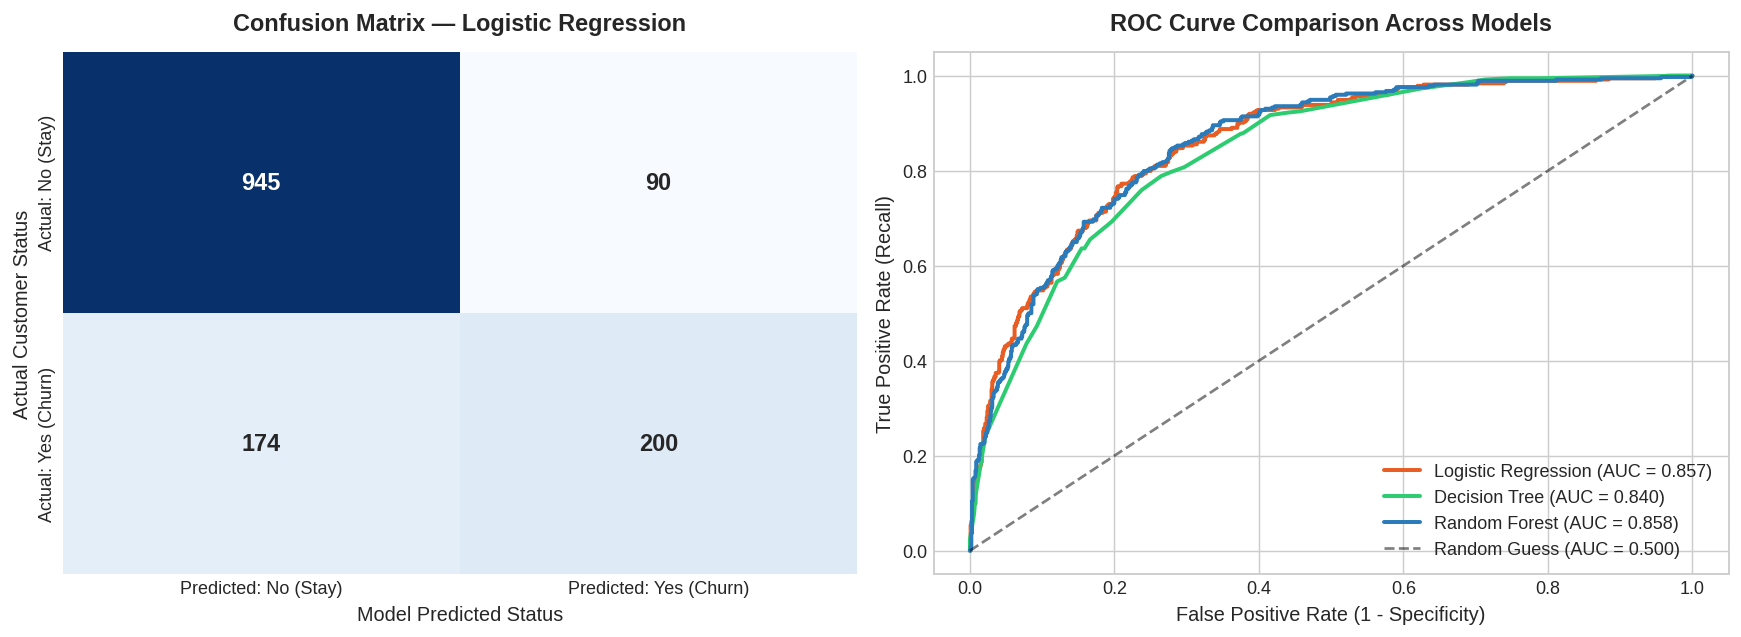

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

# Left Plot: Confusion Matrix for our best overall model (Logistic Regression)
cm = confusion_matrix(y_test, model_preds['Logistic Regression'])
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
    xticklabels=['Predicted: No (Stay)', 'Predicted: Yes (Churn)'],
    yticklabels=['Actual: No (Stay)', 'Actual: Yes (Churn)'],
    annot_kws={'size': 13, 'weight': 'bold'}
)
axes[0].set_title('Confusion Matrix — Logistic Regression', fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel('Actual Customer Status', fontsize=11)
axes[0].set_xlabel('Model Predicted Status', fontsize=11)

# Right Plot: ROC Curves for all 3 models
colors_roc = {'Logistic Regression': '#E85D24', 'Random Forest': '#2B7BBA', 'Decision Tree': '#2ECC71'}
for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, model_probs[name])
    auc_val = roc_auc_score(y_test, model_probs[name])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", color=colors_roc[name], linewidth=2.2)

axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Guess (AUC = 0.500)')
axes[1].set_title('ROC Curve Comparison Across Models', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
axes[1].set_ylabel('True Positive Rate (Recall)', fontsize=11)
axes[1].legend(loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()

# Print detailed Classification Report for Logistic Regression
print("--- Detailed Classification Report (Logistic Regression) ---")
print(classification_report(y_test, model_preds['Logistic Regression'], target_names=['Retained (No)', 'Churned (Yes)']))

###  Feature Importance: What Did Our Models Learn?

One of the best ways to check if our Machine Learning models make sense is to inspect **Feature Importance** (from Random Forest) and **Model Coefficients** (from Logistic Regression). Do the models agree with the charts I built in my **Power BI Dashboard**? Let's check!

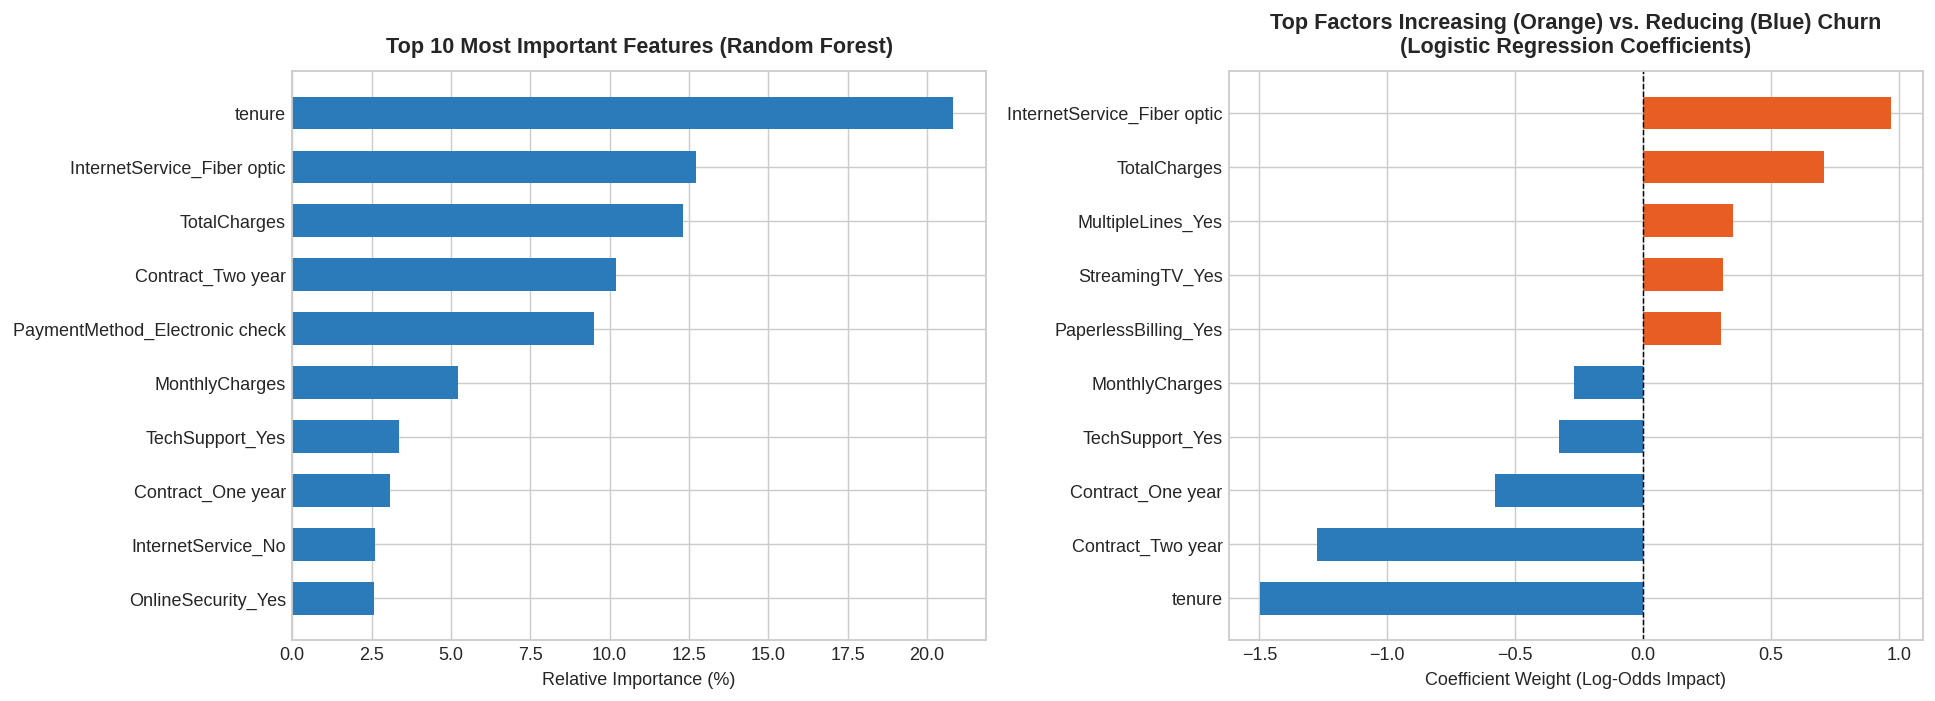

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Random Forest Top 10 Feature Importances
rf_model = models['Random Forest']
rf_imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True).tail(10)
axes[0].barh(rf_imp.index, rf_imp.values * 100, color='#2B7BBA', height=0.6)
axes[0].set_title('Top 10 Most Important Features (Random Forest)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Relative Importance (%)', fontsize=10)

# 2. Logistic Regression Top Drivers (Positive = Increases Churn, Negative = Reduces Churn)
lr_model = models['Logistic Regression']
lr_coefs = pd.Series(lr_model.coef_[0], index=X.columns)
top_coefs = pd.concat([lr_coefs.sort_values().head(5), lr_coefs.sort_values().tail(5)])
coef_colors = ['#2B7BBA' if c < 0 else '#E85D24' for c in top_coefs.values]

axes[1].barh(top_coefs.index, top_coefs.values, color=coef_colors, height=0.6)
axes[1].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('Top Factors Increasing (Orange) vs. Reducing (Blue) Churn\n(Logistic Regression Coefficients)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Coefficient Weight (Log-Odds Impact)', fontsize=10)

plt.tight_layout()
plt.show()

##  Step 7: Final Conclusion & Business Recommendations

### 1. Summary of What I Found (Connecting Power BI + Python):
- **Overall Churn Rate:** Out of `7,043` customers, `1,869` (`26.54%`) left the company.
- **Top Churn Drivers:** Both my **Power BI Dashboard** and my **Python Machine Learning models** point to the exact same root causes:
  1. **Month-to-Month Contracts (`42.7%` churn)** vs. **Two-Year Contracts (`2.8%` churn)**.
  2. **New Customers in Their First 6–12 Months (`median tenure = 10 months` for churners)**.
  3. **Fiber Optic Internet Users (`41.9%` churn)** paying higher monthly bills (`$74.44` average for churners vs. `$61.27` for retained customers) without **Tech Support (`41.6%` churn)** or **Online Security (`41.8%` churn)**.
  4. **Electronic Check Payment Method (`45.3%` churn)** compared to automatic payments (`15%–17%` churn).
- **Model Performance:** **Logistic Regression** and **Random Forest** both achieved **`~80%` Accuracy** and **`~84%` ROC-AUC** on unseen test data, with Logistic Regression catching more actual churners (**`55.3%` Recall**).

---

### 2. Actionable Business Recommendations:
1. **convert Month-to-Month Users to 1-Year Plans:** Offer a small loyalty discount (e.g., 10% off for the first 3 months) when a Month-to-Month customer upgrades to a 1-year contract.
2. **Early Onboarding Care (Months 1 to 6):** Since most churn happens in the first few months, set up automated check-in calls or usage tips during a customer's first 90 days.
3. **Bundle Free Tech Support & Online Security with Fiber Optic Plans:** Fiber Optic users pay high monthly charges and leave when they face technical issues. Including a 6-month trial of Tech Support + Online Security can drastically cut their `41.9%` churn rate.
4. **Nudge Electronic Check Customers to Auto-Pay:** Give a `$5` one-time bill credit to customers who switch from manual Electronic Check (`45.3%` churn) to automatic Credit Card or Bank Transfer (`~16%` churn).